# DeepConvLSTM workshop — Kaggle GPU version

This notebook includes the workshop code. No separate code ZIP or Google
Drive mount is needed. Training settings and experiment definitions match
the supplied workshop package.

1. Import this .ipynb into a Kaggle notebook.
2. In Session options, select an available GPU accelerator and enable Internet.
   Kaggle may require account or phone verification first. GPU availability
   and quota depend on your account and current capacity.
3. Run Cells 1–3, then Cell 4 for the reference. Train Parts A–F separately.

To reuse processed data from Colab, download
`MyDrive/deepconvlstm_workshop/data/opportunity.npz`, upload it as a private
Kaggle dataset, and attach it through Add Input. Cell 2 detects the file.
Otherwise it downloads and prepares the official dataset.

There are 13 training runs. Their full duration has not been benchmarked on
Kaggle. An unfinished Colab run starts again here; optimizer-state resuming
is not implemented. Completed experiment outputs should be saved before
ending your Kaggle session.


## Cell 1 — Unpack the included code and check the GPU

Enable Internet for package installation and the dataset download. This
cell verifies GPU access before starting a full training run.


In [1]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
import base64
import hashlib
import os
import sys
import subprocess
import shutil

# The supplied workshop package is included in this notebook.
PACKAGE_B64 = '...'
EXPECTED_SHA256 = '9629c3d11dfac9856349550e8c5c0715f29b287b2791817acce2e54fe8111776'
package_bytes = base64.b64decode(PACKAGE_B64)
if hashlib.sha256(package_bytes).hexdigest() != EXPECTED_SHA256:
    raise ValueError('The embedded package is incomplete. Import the notebook again.')

PROJECT = Path('/kaggle/working/deepconvlstm_workshop')
PROJECT.mkdir(parents=True, exist_ok=True)
with ZipFile(BytesIO(package_bytes)) as archive:
    for entry in archive.infolist():
        if entry.is_dir():
            continue
        relative = PurePosixPath(entry.filename).relative_to('deepconvlstm')
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Invalid path in the embedded package.')
        target = PROJECT.joinpath(*relative.parts)
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(entry))

os.chdir(PROJECT)

def run(*arguments):
    environment = os.environ.copy()
    environment['PYTHONUNBUFFERED'] = '1'
    subprocess.run([sys.executable, '-u', *map(str, arguments)],
                   cwd=PROJECT, env=environment, check=True)

import torch
print('PyTorch:', torch.__version__)
print('CUDA build:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError(
        'Kaggle has not provided a usable GPU. In Session options, enable a GPU '
        'accelerator. Complete account verification if Kaggle requests it. '
        'Run this cell again after the session restarts.'
    )
print('GPU:', torch.cuda.get_device_name(0))
run('-m', 'pip', 'install', '-q', '-r', 'requirements.txt')
print('Project:', PROJECT)
print('SETUP SUCCESSFUL')
run('workshop.py', '--list')


PyTorch: 2.11.0+cu128
CUDA build: 12.8
GPU: Tesla T4
Project: /kaggle/working/deepconvlstm_workshop
SETUP SUCCESSFUL
13 runs: paper reference, A/B/C/E/F, and four runs for Part D.
All use seed=0, 100 epochs maximum, patience=20 unless overridden.
Part D variants must be compared with D_ref, not the paper reference.

ref                     baseline=(baseline) (unchanged)
A_cnn                   baseline=ref        --model cnn
A_gru                   baseline=ref        --rnn gru
B_conv1                 baseline=ref        --n-conv 1
B_conv2                 baseline=ref        --n-conv 2
C_w20                   baseline=ref        --window 20
C_w60                   baseline=ref        --window 60
D_ref                   baseline=(baseline) --weight-decay 1e-4 --augment
D_no_dropout            baseline=D_ref      --weight-decay 1e-4 --augment --dropout 0
D_no_weight_decay       baseline=D_ref      --augment
D_no_augmentation       baseline=D_ref      --weight-decay 1e-4
E_warmup5       

## Cell 2 — Reuse processed data or download and prepare it

If you attached your own opportunity.npz through Add Input, this cell copies
it into the project. Otherwise it uses the official download and supplied
preprocessing script. Keep your own processed dataset private.


In [2]:
DATA = PROJECT / 'data' / 'opportunity.npz'
DATA.parent.mkdir(parents=True, exist_ok=True)
attached_data = sorted(Path('/kaggle/input').rglob('opportunity.npz'))

if DATA.is_file():
    print('Reusing the prepared dataset from this working session.')
elif len(attached_data) == 1:
    shutil.copy2(attached_data[0], DATA)
    print('Copied your prepared dataset:', attached_data[0])
elif len(attached_data) > 1:
    raise ValueError('Attach only one opportunity.npz dataset, then rerun this cell.')
else:
    print('Downloading and preprocessing the official dataset.')
    run('download_data.py', '--out', '/tmp/opportunity_raw')
    run('preprocess.py', '--raw', '/tmp/opportunity_raw', '--out', DATA)

print('Dataset:', DATA)
print('Size:', round(DATA.stat().st_size / 1024**2, 1), 'MiB')
print('DATA READY')


 -> /tmp/opportunity_raw/opportunity.zip (about 300 MB, this can take a while)
Unzipping ...
Done. Next: python preprocess.py --raw /tmp/opportunity_raw
train S1-ADL1     51116 samples
train S1-ADL2     32224 samples
train S1-ADL3     33273 samples
train S1-ADL4     32955 samples
train S1-ADL5     30127 samples
train S1-Drill    54966 samples
train S2-ADL1     42797 samples
train S2-ADL2     30182 samples
train S2-Drill    53398 samples
train S3-ADL1     37223 samples
train S3-ADL2     27825 samples
train S3-Drill    70928 samples
val   S2-ADL3     34232 samples
val   S3-ADL3     26717 samples
test  S2-ADL4     32748 samples
test  S2-ADL5     31826 samples
test  S3-ADL4     27681 samples
test  S3-ADL5     26495 samples
Saved /kaggle/working/deepconvlstm_workshop/data/opportunity.npz
  train: (497014, 113)
  val: (60949, 113)
  test: (118750, 113)
Dataset: /kaggle/working/deepconvlstm_workshop/data/opportunity.npz
Size: 123.3 MiB
DATA READY


## Cell 3 — Shared training settings

Keep the same 100 maximum epochs and seed 0 across final comparisons.
Early stopping uses validation weighted F1 with patience 20. Device auto
uses the GPU verified in Cell 1. This code uses one GPU.

Completed runs are skipped only when their saved settings match. Interrupted
runs start from epoch 1. Settings conflicts are reported before overwriting.


In [3]:
EPOCHS = 100
SEED = 0
DEVICE = 'auto'

def run_part(part):
    if not (PROJECT / 'data' / 'opportunity.npz').is_file():
        raise FileNotFoundError('Run Cell 2 to prepare the dataset first.')
    run('workshop.py', '--part', part,
        '--epochs', EPOCHS, '--seed', SEED, '--device', DEVICE)


## Cell 4 — Train the reference model

This starts a full reference run: four convolutional layers, two LSTM layers,
dropout 0.5, cross entropy, and 24-sample windows. Test results are calculated
using the checkpoint selected by validation weighted F1.


In [4]:
run_part('ref')



Running ref; comparison baseline: this is a baseline
[ref_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 3,965,778
epoch   1  lr 0.001  train_loss[cross_entropy] 1.0629  val_CE 0.5854  val_F1w 0.7956  val_F1m 0.2263  (18s) *
epoch   2  lr 0.001  train_loss[cross_entropy] 0.6062  val_CE 0.4891  val_F1w 0.8280  val_F1m 0.3207  (35s) *
epoch   3  lr 0.001  train_loss[cross_entropy] 0.5112  val_CE 0.5295  val_F1w 0.8180  val_F1m 0.2968  (52s)
epoch   4  lr 0.001  train_loss[cross_entropy] 0.4604  val_CE 0.4926  val_F1w 0.8340  val_F1m 0.3625  (70s) *
epoch   5  lr 0.001  train_loss[cross_entropy] 0.4267  val_CE 0.5253  val_F1w 0.8345  val_F1m 0.3695  (89s) *
epoch   6  lr 0.001  train_loss[cross_entropy] 0.3976  val_CE 0.4873  val_F1w 0.8471  val_F1m 0.4074  (108s) *
epoch   7  lr 0.001  train_loss[cross_entropy] 0.3752  val_CE 0.4827  val_F1w 0.8540  val_F1m 0.4573  (127s) *
epoch   8  lr 0.001  train_loss[cross_entropy] 0.3557  val_CE 0.4

## Cell 5 — Part A

Compare CNN and GRU with the LSTM reference (two runs).

Run this cell when you are ready to start this part.


In [5]:
run_part('A')



Running A_cnn; comparison baseline: ref
[A_cnn_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 7,486,546
epoch   1  lr 0.001  train_loss[cross_entropy] 1.3116  val_CE 0.6596  val_F1w 0.7633  val_F1m 0.1099  (17s) *
epoch   2  lr 0.001  train_loss[cross_entropy] 0.8636  val_CE 0.5718  val_F1w 0.7888  val_F1m 0.2128  (34s) *
epoch   3  lr 0.001  train_loss[cross_entropy] 0.7305  val_CE 0.6066  val_F1w 0.7763  val_F1m 0.1600  (51s)
epoch   4  lr 0.001  train_loss[cross_entropy] 0.6745  val_CE 0.5285  val_F1w 0.7976  val_F1m 0.2390  (67s) *
epoch   5  lr 0.001  train_loss[cross_entropy] 0.6662  val_CE 0.5161  val_F1w 0.8137  val_F1m 0.2927  (84s) *
epoch   6  lr 0.001  train_loss[cross_entropy] 0.6252  val_CE 0.5196  val_F1w 0.8159  val_F1m 0.3076  (100s) *
epoch   7  lr 0.001  train_loss[cross_entropy] 0.6095  val_CE 0.5919  val_F1w 0.7984  val_F1m 0.2515  (116s)
epoch   8  lr 0.001  train_loss[cross_entropy] 0.6258  val_CE 0.4817  val_F1w 

## Cell 6 — Part B

Use one and two convolutional layers (two runs).

Run this cell when you are ready to start this part.


In [6]:
run_part('B')



Running B_conv1; comparison baseline: ref
[B_conv1_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 3,904,146
epoch   1  lr 0.001  train_loss[cross_entropy] 1.2133  val_CE 0.6431  val_F1w 0.7759  val_F1m 0.1610  (9s) *
epoch   2  lr 0.001  train_loss[cross_entropy] 0.6454  val_CE 0.5239  val_F1w 0.8092  val_F1m 0.2586  (18s) *
epoch   3  lr 0.001  train_loss[cross_entropy] 0.4981  val_CE 0.5005  val_F1w 0.8318  val_F1m 0.3679  (28s) *
epoch   4  lr 0.001  train_loss[cross_entropy] 0.4217  val_CE 0.5370  val_F1w 0.8251  val_F1m 0.3770  (38s)
epoch   5  lr 0.001  train_loss[cross_entropy] 0.3715  val_CE 0.4272  val_F1w 0.8539  val_F1m 0.4547  (48s) *
epoch   6  lr 0.001  train_loss[cross_entropy] 0.3391  val_CE 0.4385  val_F1w 0.8592  val_F1m 0.4733  (57s) *
epoch   7  lr 0.001  train_loss[cross_entropy] 0.3079  val_CE 0.4499  val_F1w 0.8621  val_F1m 0.4711  (66s) *
epoch   8  lr 0.001  train_loss[cross_entropy] 0.2837  val_CE 0.4890  val_F

## Cell 7 — Part C

Use 20-sample and 60-sample windows (two runs).

Run this cell when you are ready to start this part.


In [7]:
run_part('C')



Running C_w20; comparison baseline: ref
[C_w20_s0] device=cuda  windows train/val/test = 41405/5077/9892  channels=113  classes=18
parameters: 3,965,778
epoch   1  lr 0.001  train_loss[cross_entropy] 1.0430  val_CE 0.6866  val_F1w 0.7677  val_F1m 0.1363  (14s) *
epoch   2  lr 0.001  train_loss[cross_entropy] 0.6055  val_CE 0.5123  val_F1w 0.8253  val_F1m 0.3234  (27s) *
epoch   3  lr 0.001  train_loss[cross_entropy] 0.5137  val_CE 0.5603  val_F1w 0.8150  val_F1m 0.2943  (41s)
epoch   4  lr 0.001  train_loss[cross_entropy] 0.4659  val_CE 1.0539  val_F1w 0.7630  val_F1m 0.1529  (55s)
epoch   5  lr 0.001  train_loss[cross_entropy] 0.4300  val_CE 0.5895  val_F1w 0.8203  val_F1m 0.3109  (68s)
epoch   6  lr 0.001  train_loss[cross_entropy] 0.4021  val_CE 0.5160  val_F1w 0.8388  val_F1m 0.3745  (81s) *
epoch   7  lr 0.001  train_loss[cross_entropy] 0.3771  val_CE 0.4963  val_F1w 0.8577  val_F1m 0.4462  (94s) *
epoch   8  lr 0.001  train_loss[cross_entropy] 0.3578  val_CE 0.4960  val_F1w 0.84

## Cell 8 — Part D

Train a baseline with dropout, weight decay 0.0001, and augmentation enabled; then remove one regularizer at a time (four runs). Compare all D variants with D_ref. This extra baseline is necessary because the original reference already has weight decay and augmentation disabled.

Run this cell when you are ready to start this part.


In [8]:
run_part('D')



Running D_ref; comparison baseline: this is a baseline
[D_ref_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 3,965,778
epoch   1  lr 0.001  train_loss[cross_entropy] 1.1558  val_CE 0.6346  val_F1w 0.7774  val_F1m 0.1706  (19s) *
epoch   2  lr 0.001  train_loss[cross_entropy] 0.7567  val_CE 0.5678  val_F1w 0.7858  val_F1m 0.1903  (39s) *
epoch   3  lr 0.001  train_loss[cross_entropy] 0.6751  val_CE 0.5943  val_F1w 0.7983  val_F1m 0.2578  (58s) *
epoch   4  lr 0.001  train_loss[cross_entropy] 0.6282  val_CE 0.5143  val_F1w 0.8209  val_F1m 0.3102  (77s) *
epoch   5  lr 0.001  train_loss[cross_entropy] 0.5938  val_CE 0.5457  val_F1w 0.8232  val_F1m 0.3319  (95s) *
epoch   6  lr 0.001  train_loss[cross_entropy] 0.5696  val_CE 0.5231  val_F1w 0.8200  val_F1m 0.3109  (114s)
epoch   7  lr 0.001  train_loss[cross_entropy] 0.5498  val_CE 0.4777  val_F1w 0.8312  val_F1m 0.3388  (133s) *
epoch   8  lr 0.001  train_loss[cross_entropy] 0.5326  val_CE

## Cell 9 — Part E

Increase the learning rate over the first five epochs, then compare with the reference (one run).

Run this cell when you are ready to start this part.


In [9]:
run_part('E')



Running E_warmup5; comparison baseline: ref
[E_warmup5_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 3,965,778
epoch   1  lr 0.0002  train_loss[cross_entropy] 1.3238  val_CE 0.7377  val_F1w 0.7598  val_F1m 0.1086  (19s) *
epoch   2  lr 0.0004  train_loss[cross_entropy] 0.7818  val_CE 0.5038  val_F1w 0.8154  val_F1m 0.2782  (39s) *
epoch   3  lr 0.0006  train_loss[cross_entropy] 0.5764  val_CE 0.5678  val_F1w 0.8101  val_F1m 0.2766  (58s)
epoch   4  lr 0.0008  train_loss[cross_entropy] 0.5025  val_CE 0.5247  val_F1w 0.8283  val_F1m 0.3749  (77s) *
epoch   5  lr 0.001  train_loss[cross_entropy] 0.4572  val_CE 0.5071  val_F1w 0.8453  val_F1m 0.4136  (95s) *
epoch   6  lr 0.001  train_loss[cross_entropy] 0.3976  val_CE 0.4891  val_F1w 0.8592  val_F1m 0.4602  (114s) *
epoch   7  lr 0.001  train_loss[cross_entropy] 0.3559  val_CE 0.4679  val_F1w 0.8601  val_F1m 0.4615  (133s) *
epoch   8  lr 0.001  train_loss[cross_entropy] 0.3302  val_CE 0.

## Cell 10 — Part F

Use Focal Loss with gamma 2 instead of cross entropy (one run). Inspect macro F1 and the rare classes as well as weighted F1.

Run this cell when you are ready to start this part.


In [10]:
run_part('F')



Running F_focal; comparison baseline: ref
[F_focal_s0] device=cuda  windows train/val/test = 41399/5076/9890  channels=113  classes=18
parameters: 3,965,778
epoch   1  lr 0.001  train_loss[focal] 0.7422  val_CE 0.6822  val_F1w 0.7946  val_F1m 0.2481  (20s) *
epoch   2  lr 0.001  train_loss[focal] 0.3580  val_CE 0.5303  val_F1w 0.8143  val_F1m 0.2969  (39s) *
epoch   3  lr 0.001  train_loss[focal] 0.2768  val_CE 0.5407  val_F1w 0.8012  val_F1m 0.2436  (58s)
epoch   4  lr 0.001  train_loss[focal] 0.2399  val_CE 0.5450  val_F1w 0.8325  val_F1m 0.3647  (77s) *
epoch   5  lr 0.001  train_loss[focal] 0.2162  val_CE 0.5427  val_F1w 0.8249  val_F1m 0.3389  (95s)
epoch   6  lr 0.001  train_loss[focal] 0.1953  val_CE 0.5112  val_F1w 0.8347  val_F1m 0.3809  (114s) *
epoch   7  lr 0.001  train_loss[focal] 0.1796  val_CE 0.4557  val_F1w 0.8548  val_F1m 0.4399  (133s) *
epoch   8  lr 0.001  train_loss[focal] 0.1704  val_CE 0.4669  val_F1w 0.8509  val_F1m 0.4296  (152s)
epoch   9  lr 0.001  train_lo

## Cell 11 — Results table

You can run this after any completed experiment. It includes the completed
runs only. Part D uses its own baseline for score differences.


In [11]:
run('workshop.py', '--summary')

import pandas as pd
from IPython.display import display

TABLE = PROJECT / 'workshop_comparison.csv'
if TABLE.is_file():
    results = pd.read_csv(TABLE)
    display(results)
    print('Saved:', TABLE)
else:
    print('Complete a training run before creating the results table.')


ref_s0                      F1w=0.8873 F1m=0.5912 compare=baseline
A_cnn_s0                    F1w=0.8629 F1m=0.4461 compare=ref_s0
A_gru_s0                    F1w=0.8938 F1m=0.6093 compare=ref_s0
B_conv1_s0                  F1w=0.8879 F1m=0.5755 compare=ref_s0
B_conv2_s0                  F1w=0.8989 F1m=0.6347 compare=ref_s0
C_w20_s0                    F1w=0.8908 F1m=0.5814 compare=ref_s0
C_w60_s0                    F1w=0.8986 F1m=0.6208 compare=ref_s0
D_ref_s0                    F1w=0.8873 F1m=0.5739 compare=baseline
D_no_dropout_s0             F1w=0.8881 F1m=0.5861 compare=D_ref_s0
D_no_weight_decay_s0        F1w=0.8896 F1m=0.5762 compare=D_ref_s0
D_no_augmentation_s0        F1w=0.8843 F1m=0.5657 compare=D_ref_s0
E_warmup5_s0                F1w=0.8897 F1m=0.6009 compare=ref_s0
F_focal_s0                  F1w=0.8944 F1m=0.5873 compare=ref_s0
Saved workshop_comparison.csv (deltas are score differences, not percentage changes).


,run,part,seed,compare_with,weighted_F1,macro_F1,accuracy,delta_weighted_F1,delta_macro_F1,parameters,best_epoch,training_minutes,window,n_conv,dropout,weight_decay,augmentation,loss,warmup_epochs
0,ref_s0,ref,0,baseline,0.887289,0.591189,0.889788,NaN,NaN,3965778,38,17.779274,24,4,0.5,0.0000,False,cross_entropy,0
1,A_cnn_s0,A,0,ref_s0,0.862902,0.446128,0.874823,-0.024387,-0.145061,7486546,29,13.110393,24,4,0.5,0.0000,False,cross_entropy,0
2,A_gru_s0,A,0,ref_s0,0.893818,0.609260,0.894944,0.006529,0.018071,2990418,22,12.395020,24,4,0.5,0.0000,False,cross_entropy,0
3,B_conv1_s0,B,0,ref_s0,0.887949,0.575516,0.886855,0.000660,-0.015673,3904146,25,6.976684,24,1,0.5,0.0000,False,cross_entropy,0
4,B_conv2_s0,B,0,ref_s0,0.898938,0.634658,0.901011,0.011649,0.043469,3924690,23,9.669343,24,2,0.5,0.0000,False,cross_entropy,0
5,C_w20_s0,C,0,ref_s0,0.890831,0.581354,0.889507,0.003541,-0.009834,3965778,25,9.880594,20,4,0.5,0.0000,False,cross_entropy,0
6,C_w60_s0,C,0,ref_s0,0.898572,0.620770,0.898056,0.011282,0.029582,3965778,16,42.680967,60,4,0.5,0.0000,False,cross_entropy,0
7,D_ref_s0,D,0,baseline,0.887293,0.573922,0.889687,NaN,NaN,3965778,42,19.340495,24,4,0.5,0.0001,True,cross_entropy,0
8,D_no_dropout_s0,D,0,D_ref_s0,0.888145,0.586122,0.890799,0.000852,0.012200,3965778,46,20.366791,24,4,0.0,0.0001,True,cross_entropy,0
9,D_no_weight_decay_s0,D,0,D_ref_s0,0.889611,0.576210,0.891001,0.002317,0.002288,3965778,43,19.423868,24,4,0.5,0.0000,True,cross_entropy,0


Saved: /kaggle/working/deepconvlstm_workshop/workshop_comparison.csv


## Cell 12 — View a run's plots and class report

Change RUN_NAME to a completed run, for example ref_s0, A_cnn_s0,
D_ref_s0, or F_focal_s0. All plots and checkpoints are saved in the runs folder.


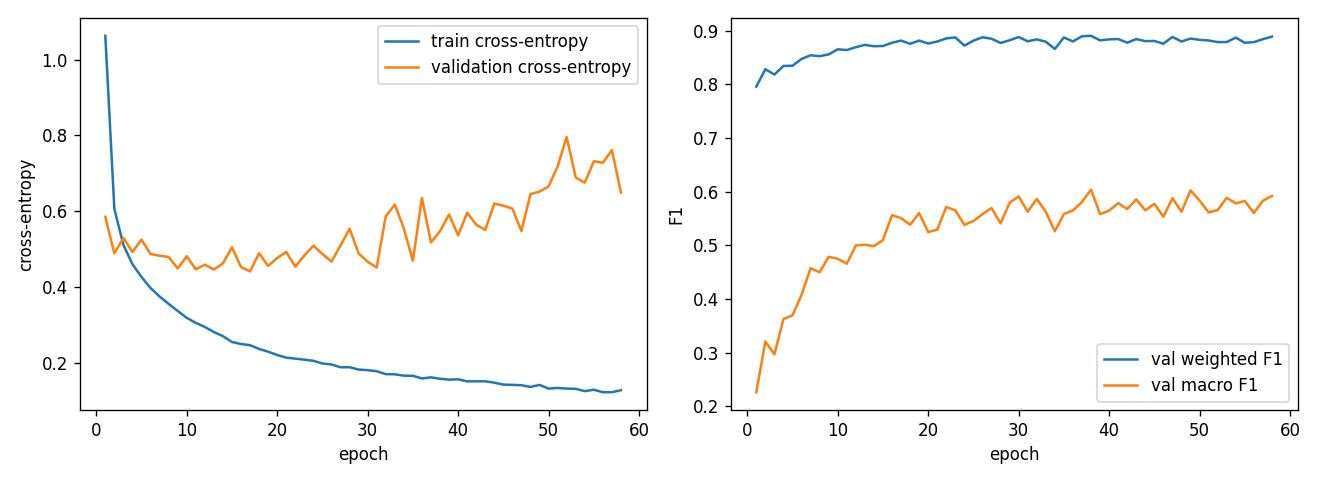

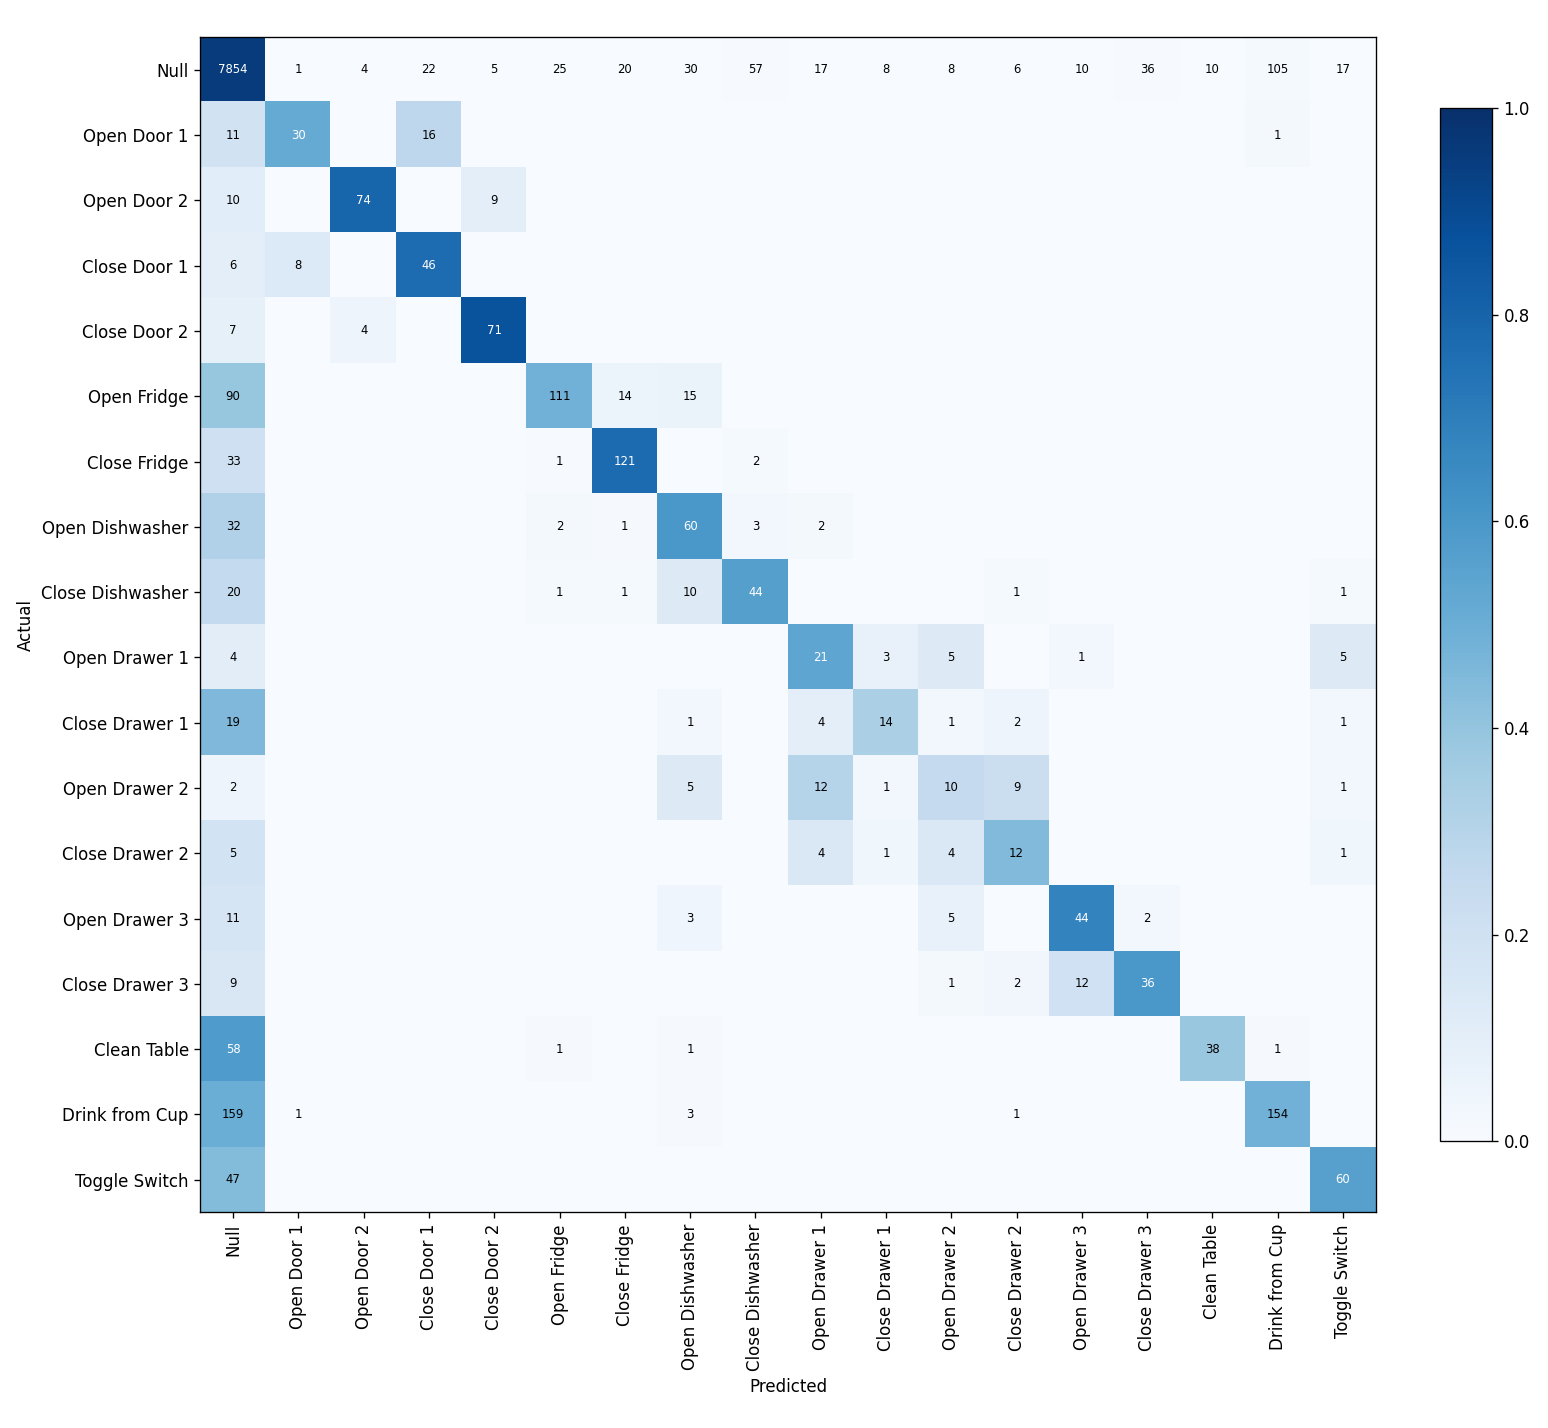

                  precision    recall  f1-score   support

            Null      0.938     0.954     0.946      8235
     Open Door 1      0.750     0.517     0.612        58
     Open Door 2      0.902     0.796     0.846        93
    Close Door 1      0.548     0.767     0.639        60
    Close Door 2      0.835     0.866     0.850        82
     Open Fridge      0.787     0.483     0.598       230
    Close Fridge      0.771     0.771     0.771       157
 Open Dishwasher      0.469     0.600     0.526       100
Close Dishwasher      0.415     0.564     0.478        78
   Open Drawer 1      0.350     0.538     0.424        39
  Close Drawer 1      0.519     0.333     0.406        42
   Open Drawer 2      0.294     0.250     0.270        40
  Close Drawer 2      0.364     0.444     0.400        27
   Open Drawer 3      0.657     0.677     0.667        65
  Close Drawer 3      0.486     0.600     0.537        60
     Clean Table      0.792     0.384     0.517        99
  Drink from 

In [12]:
from IPython.display import Image, display

RUN_NAME = f'ref_s{SEED}'
RUN_FOLDER = PROJECT / 'runs' / RUN_NAME
for filename in ('learning_curves.png', 'confusion_matrix.png'):
    plot = RUN_FOLDER / filename
    if plot.is_file():
        display(Image(filename=str(plot)))
    else:
        print('Not available yet:', plot.name)

report = RUN_FOLDER / 'classification_report.txt'
if report.is_file():
    print(report.read_text())


## Cell 13 — Package code and completed results for download

This creates /kaggle/working/deepconvlstm_submission_outputs.zip. Download
it from Kaggle's Output or Files pane before ending the session. It contains
source code, tables, plots, and reports; raw data and model weights are
excluded. This ZIP does not contain a resume checkpoint or a written report.


In [5]:
OUTPUT_ZIP = Path('/kaggle/working/deepconvlstm_submission_outputs.zip')
allowed = {'.py', '.md', '.csv', '.png', '.txt', '.json'}
with ZipFile(OUTPUT_ZIP, 'w', compression=8) as archive:
    for path in sorted(PROJECT.rglob('*')):
        relative = path.relative_to(PROJECT)
        if not path.is_file() or '__pycache__' in relative.parts:
            continue
        if relative.parts[0] == 'data':
            continue
        if path.suffix.lower() in allowed or path.name == '.gitignore':
            archive.write(path, arcname=str(relative))
print('Download this file from the Output / Files pane:')
print(OUTPUT_ZIP)
print('Size:', round(OUTPUT_ZIP.stat().st_size / 1024**2, 2), 'MiB')


NameError: name 'ZipFile' is not defined

In [3]:
from pathlib import Path
from IPython.display import FileLink, display
import os

zip_path = Path(
    "/kaggle/working/deepconvlstm_submission_outputs.zip"
)

if zip_path.is_file():
    os.chdir("/kaggle/working")
    print("Click the filename below to download:")
    display(FileLink(zip_path.name))
else:
    print("The ZIP is missing from the current live session.")
    print("Send me this output so we can locate the saved results.")

The ZIP is missing from the current live session.
Send me this output so we can locate the saved results.


In [6]:
from pathlib import Path

runs = Path("/kaggle/working/deepconvlstm_workshop/runs")
print("Completed result files:", len(list(runs.glob("*/metrics.json"))))

Completed result files: 0
